# Verification of the CN-ADI Advection–Dispersion Solver

This notebook checks the solver in `sim/` against a known analytic solution.

**It imports the exact same functions the website runs** — `build_grid` and
`cn_adi_step` (the production time-stepping driver `run_simulation` just calls
`cn_adi_step` in a loop). There is no second solver written for verification;
the only extra piece is `sim.analytic.gaussian_spill`, the closed-form answer we
compare against.

**Test problem.** A uniform medium (constant dispersion $D$, constant horizontal
velocity $v_x$) with an initial Gaussian spill placed away from the boundaries.
The exact solution of

$$\frac{\partial C}{\partial t} + v_x\frac{\partial C}{\partial x}
   = D\left(\frac{\partial^2 C}{\partial x^2}+\frac{\partial^2 C}{\partial z^2}\right)$$

for a Gaussian initial condition is a Gaussian that **advects** with the flow and
**spreads** as its variance grows like $2Dt$:

$$C(x,z,t)=C_0\,\frac{\sigma_0^2}{\sigma_0^2+2Dt}\,
  \exp\!\left[-\frac{(x-x_0-v_x t)^2+(z-z_0)^2}{2(\sigma_0^2+2Dt)}\right].$$

We run two cases — (1) $v_x=0$ (pure dispersion) and (2) $v_x\neq0$ (adds
advection) — then show grid-refinement convergence in $\Delta x$ and $\Delta t$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # repo root, so `import sim` works

import numpy as np
import matplotlib.pyplot as plt

# The SAME functions the website / run_simulation use:
from sim.model import build_grid
from sim.solver import cn_adi_step, cell_diagnostics
# Analytic solution, used only to check the numerical answer:
from sim.analytic import gaussian_spill

## A small helper that runs the solver on a uniform medium

This is exactly what `sim.model.run_simulation` does internally: build the grid,
set the initial condition, then step forward with `cn_adi_step`. Here we use a
Gaussian initial condition (from the analytic solution at $t=0$) so we can
compare against the analytic answer at the end.

In [2]:
# March the Gaussian spill to time T on a uniform medium; return the grid,
# the numerical field, and the analytic field at T.
def run_uniform(D, vx, dx, dt, T, length=2.0, depth=2.0,
                C0=1.0, x0=1.0, z0=1.0, sigma0=0.1):
    g = build_grid(length, depth, dx, dx)          # dz = dx here
    # Initial condition = analytic Gaussian at t = 0
    C = gaussian_spill(g.X, g.Z, 0.0, C0, x0, z0, sigma0, D, vx)
    nt = int(round(T / dt))
    for _ in range(nt):
        C = cn_adi_step(C, D, vx, g.dx, g.dz, dt)   # THE solver
    C_exact = gaussian_spill(g.X, g.Z, nt * dt, C0, x0, z0, sigma0, D, vx)
    return g, C, C_exact


def l2_error(C, C_exact):                           # root-mean-square error
    return np.sqrt(np.mean((C - C_exact) ** 2))


def max_error(C, C_exact):                          # largest pointwise error
    return np.max(np.abs(C - C_exact))

## Part 1 — Pure dispersion ($v_x = 0$)

This is the parabolic (diffusion-only) case, like Lab 4 Part 1. We plot the
numerical solution, the analytic solution, and their difference.

Pe = 0.000   Cr = 0.000
L2 error  = 3.928e-05
max error = 3.180e-04


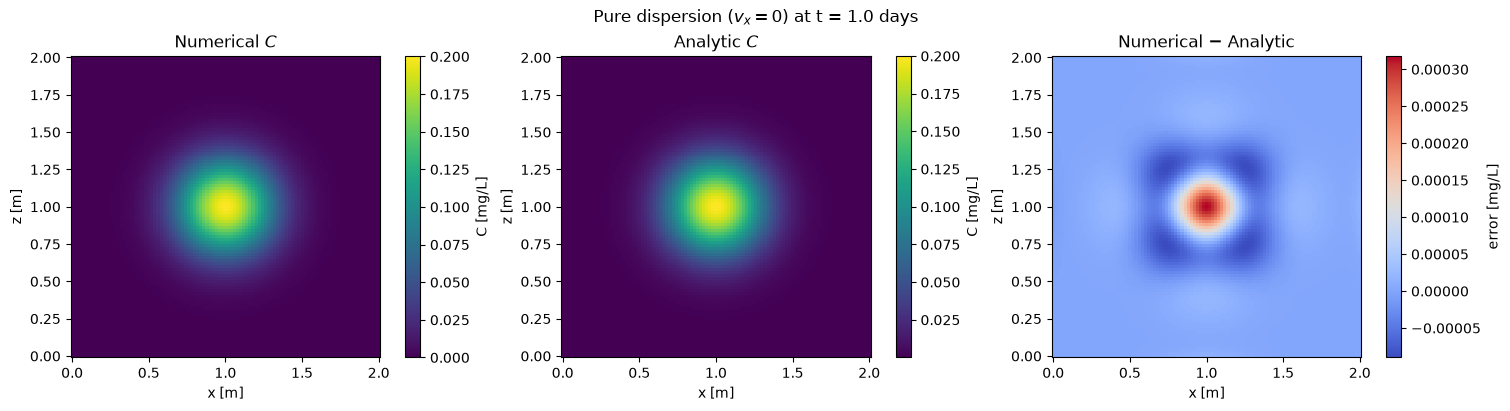

In [3]:
D, vx = 0.02, 0.0
dx, dt, T = 0.02, 0.01, 1.0

g, C, C_exact = run_uniform(D, vx, dx, dt, T)
Pe, Cr = cell_diagnostics(D, vx, dx, dt)
print(f"Pe = {Pe:.3f}   Cr = {Cr:.3f}")
print(f"L2 error  = {l2_error(C, C_exact):.3e}")
print(f"max error = {max_error(C, C_exact):.3e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
im0 = ax[0].pcolormesh(g.X, g.Z, C, shading='auto', cmap='viridis')
ax[0].set_title('Numerical $C$'); fig.colorbar(im0, ax=ax[0], label='C [mg/L]')
im1 = ax[1].pcolormesh(g.X, g.Z, C_exact, shading='auto', cmap='viridis')
ax[1].set_title('Analytic $C$'); fig.colorbar(im1, ax=ax[1], label='C [mg/L]')
im2 = ax[2].pcolormesh(g.X, g.Z, C - C_exact, shading='auto', cmap='coolwarm')
ax[2].set_title('Numerical $-$ Analytic'); fig.colorbar(im2, ax=ax[2], label='error [mg/L]')
for a in ax:
    a.set_xlabel('x [m]'); a.set_ylabel('z [m]')
fig.suptitle(f'Pure dispersion ($v_x=0$) at t = {T} days')
plt.show()

## Part 2 — Advection + dispersion ($v_x \neq 0$)

Now the plume should both spread **and** drift downstream at speed $v_x$. The
centre of mass should sit at $x_0 + v_x t$.

Pe = 0.200   Cr = 0.100
L2 error  = 7.796e-05
max error = 5.037e-04
x centroid: numerical = 1.2000, expected x0+vx*T = 1.2000


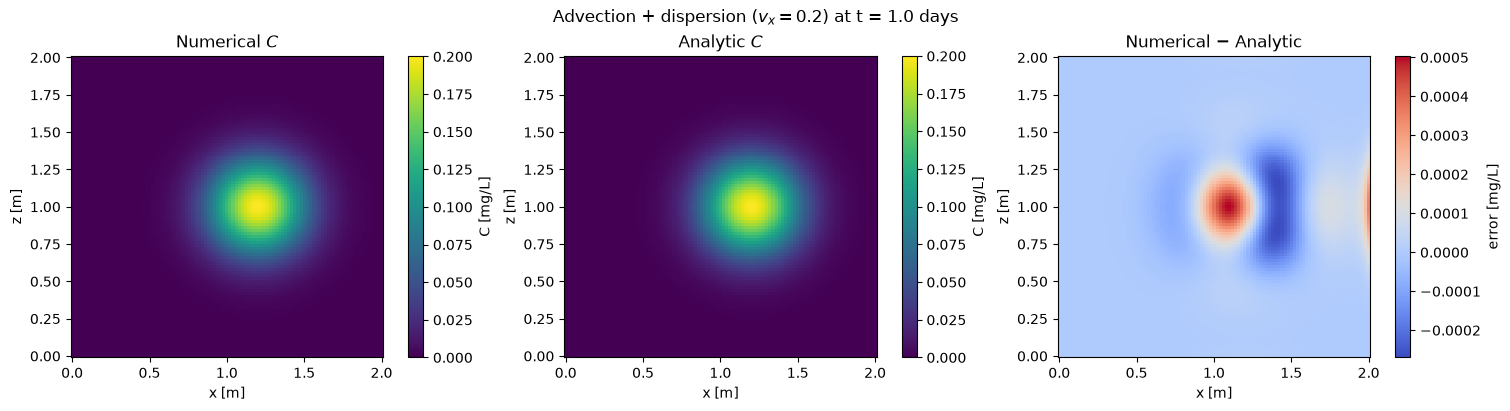

In [4]:
D, vx = 0.02, 0.2
dx, dt, T = 0.02, 0.01, 1.0

g, C, C_exact = run_uniform(D, vx, dx, dt, T)
Pe, Cr = cell_diagnostics(D, vx, dx, dt)
print(f"Pe = {Pe:.3f}   Cr = {Cr:.3f}")
print(f"L2 error  = {l2_error(C, C_exact):.3e}")
print(f"max error = {max_error(C, C_exact):.3e}")

x_cm = np.sum(g.X * C) / np.sum(C)
print(f"x centroid: numerical = {x_cm:.4f}, expected x0+vx*T = {1.0 + vx*T:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
im0 = ax[0].pcolormesh(g.X, g.Z, C, shading='auto', cmap='viridis')
ax[0].set_title('Numerical $C$'); fig.colorbar(im0, ax=ax[0], label='C [mg/L]')
im1 = ax[1].pcolormesh(g.X, g.Z, C_exact, shading='auto', cmap='viridis')
ax[1].set_title('Analytic $C$'); fig.colorbar(im1, ax=ax[1], label='C [mg/L]')
im2 = ax[2].pcolormesh(g.X, g.Z, C - C_exact, shading='auto', cmap='coolwarm')
ax[2].set_title('Numerical $-$ Analytic'); fig.colorbar(im2, ax=ax[2], label='error [mg/L]')
for a in ax:
    a.set_xlabel('x [m]'); a.set_ylabel('z [m]')
fig.suptitle(f'Advection + dispersion ($v_x={vx}$) at t = {T} days')
plt.show()

## Convergence in space ($\Delta x$)

The spatial discretization (central differences and harmonic-mean faces) is
second-order accurate, so the error should fall like $\Delta x^2$. We keep
$\Delta t$ very small so the time error is negligible and only the **space**
error is left, then refine $\Delta x$. On log–log axes the error should follow
the dashed slope-2 reference line.

dx     L2 error
 0.080  1.346e-03
 0.040  3.341e-04
 0.020  8.381e-05
 0.010  2.101e-05
observed slope = 2.00  (expect ~2)


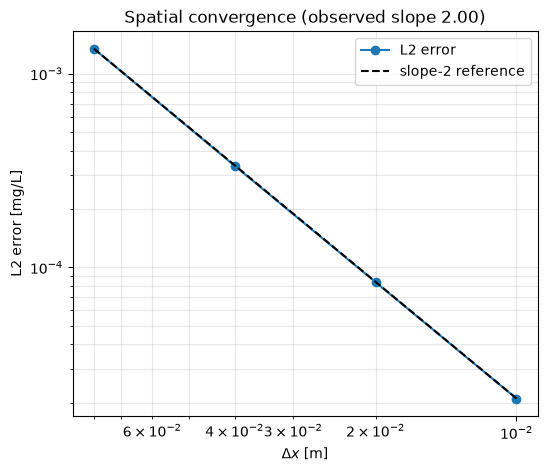

In [5]:
D, vx = 0.02, 0.1
dt_fixed, T = 0.00125, 0.5          # tiny dt so time error is negligible
dxs = np.array([0.08, 0.04, 0.02, 0.01])

errs = []
for dx in dxs:
    g, C, C_exact = run_uniform(D, vx, dx, dt_fixed, T)
    errs.append(l2_error(C, C_exact))
errs = np.array(errs)

slope = np.polyfit(np.log(dxs), np.log(errs), 1)[0]
print("dx     L2 error")
for dx, e in zip(dxs, errs):
    print(f"{dx:6.3f}  {e:.3e}")
print(f"observed slope = {slope:.2f}  (expect ~2)")

ref = errs[0] * (dxs / dxs[0]) ** 2         # slope-2 line anchored at coarsest
plt.figure(figsize=(6, 5))
plt.loglog(dxs, errs, 'o-', label='L2 error')
plt.loglog(dxs, ref, 'k--', label='slope-2 reference')
plt.gca().invert_xaxis()                    # refine to the right
plt.xlabel('$\\Delta x$ [m]'); plt.ylabel('L2 error [mg/L]')
plt.title(f'Spatial convergence (observed slope {slope:.2f})')
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.show()

## Convergence in time ($\Delta t$)

Crank–Nicolson ADI is second-order in time, so the error should fall like
$\Delta t^2$. To isolate the **time** error we keep the grid fixed and compare
each run against a reference run on the *same grid* with a very small $\Delta t$.
Because the grid is identical, the spatial error cancels and only the time error
remains — this is cleaner than comparing to the analytic solution, where the
(fixed) spatial error would hide the time trend.

dt      L2 error (vs fine-dt reference)
 0.0200  5.000e-06
 0.0100  1.246e-06
 0.0050  3.078e-07
 0.0025  7.328e-08
observed slope = 2.03  (expect ~2)


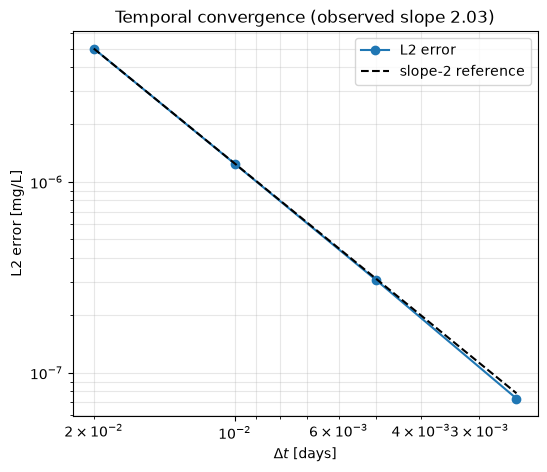

In [6]:
D, vx = 0.02, 0.1
dx_fixed, T = 0.02, 0.5

# Reference solution on the fixed grid with a very small time step
g = build_grid(2.0, 2.0, dx_fixed, dx_fixed)
def march(dt):
    C = gaussian_spill(g.X, g.Z, 0.0, 1.0, 1.0, 1.0, 0.1, D, vx)
    for _ in range(int(round(T / dt))):
        C = cn_adi_step(C, D, vx, g.dx, g.dz, dt)
    return C

C_ref = march(0.000625)
dts = np.array([0.02, 0.01, 0.005, 0.0025])

errs = np.array([l2_error(march(dt), C_ref) for dt in dts])
slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
print("dt      L2 error (vs fine-dt reference)")
for dt, e in zip(dts, errs):
    print(f"{dt:7.4f}  {e:.3e}")
print(f"observed slope = {slope:.2f}  (expect ~2)")

ref = errs[0] * (dts / dts[0]) ** 2
plt.figure(figsize=(6, 5))
plt.loglog(dts, errs, 'o-', label='L2 error')
plt.loglog(dts, ref, 'k--', label='slope-2 reference')
plt.gca().invert_xaxis()
plt.xlabel('$\\Delta t$ [days]'); plt.ylabel('L2 error [mg/L]')
plt.title(f'Temporal convergence (observed slope {slope:.2f})')
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.show()

## Discussion

**Agreement.** In both the pure-dispersion and advection cases the numerical
field matches the analytic Gaussian to a small fraction of the peak
concentration, and the plume centre of mass advects at the expected speed
$x_0+v_x t$. The error maps show the only sizeable differences sit near the
moving peak, where the solution curves most sharply.

**Convergence.** The space- and time-refinement studies both follow the dashed
slope-2 reference lines, confirming the scheme is second-order accurate in
$\Delta x$ and $\Delta t$ — as expected for Crank–Nicolson ADI with central
differences.

**Péclet and Courant.** The cell Péclet number $Pe=|v_x|\Delta x/D$ stays well
below 2 in these runs, so the central-difference advection term does not
oscillate. If $D$ is small or $\Delta x$ large, $Pe$ can exceed 2 and produce
wiggles at sharp fronts — the interface warns when this happens. The Courant
number $Cr=|v_x|\Delta t/\Delta x$ does not limit stability (Crank–Nicolson is
unconditionally stable) but large $Cr$ reduces accuracy at sharp fronts.

**Boundaries.** The analytic solution assumes an infinite domain, so we keep the
plume away from the edges; the left (fixed $C=0$), right (zero-gradient),
top/bottom (no-flux) boundaries then have a negligible effect. The small error
floor at the finest grids comes partly from the tiny but non-zero plume values
reaching the boundaries.

**Limitations.** The analytic check only covers a uniform medium. The layered /
variable-$D$ behaviour (harmonic-mean faces, per-layer velocity) and the mixed
top source boundary are exercised by the script tests in `examples/`, since no
simple closed-form solution exists for those cases.